# Quantum reference frames: the $\mathbb{Z}_2$ example

**Working notes by Ashesh Kumar Gupta**

These notes follow the three-qubit example in Castro-Ruiz, Galley and Loveridge, *Interpreting quantum-reference-frame transformations through a simple example*, Phys. Rev. A **114**, 032201 (2026). I reproduce its main calculations, implement the maps it only describes, and then explore a few extensions.

**Central question.** Two global invariant states look identical relative to Alice but orthogonal relative to Bob. What can "the change of frame from Alice to Bob" then mean?



## 0. Setup and conventions

Qubits are ordered $(A,B,C)$. The global $\mathbb{Z}_2$ action is generated by $G=X_A\otimes X_B\otimes X_C$, and $\Pi_\pm=(1\pm G)/2$ project onto the trivial sector $\mathcal H_0$ and the sign sector $\mathcal H_1$. The two global states of Eqs. (12)–(13) are built below and checked to lie in $\mathcal H_0$ and $\mathcal H_1$.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---- tiny test harness: every claim made in the text is backed by a recorded check ----
_RESULTS = []
_MARK = [0]
def check(label, condition):
    """Record a check. Only failures are printed; each section ends with a one-line report()."""
    ok = bool(condition)
    _RESULTS.append((label, ok))
    if not ok:
        print("FAIL  " + label)
    return ok

def report(section):
    """One-line summary of the checks recorded since the previous report."""
    chunk = _RESULTS[_MARK[0]:]
    _MARK[0] = len(_RESULTS)
    print(f"[{section}] {sum(ok for _, ok in chunk)}/{len(chunk)} checks passed")

# ---- single-qubit building blocks ----
I2 = np.eye(2, dtype=complex)
X  = np.array([[0, 1], [1, 0]], dtype=complex)
P0 = np.diag([1, 0]).astype(complex)                 # |0><0|
P1 = np.diag([0, 1]).astype(complex)                 # |1><1|
PROJ = (P0, P1)
KET0 = np.array([1, 0], dtype=complex)
KETP = np.array([1,  1], dtype=complex) / np.sqrt(2)  # |+>
KETM = np.array([1, -1], dtype=complex) / np.sqrt(2)  # |->
XX = np.kron(X, X)

def kron(*ops):
    out = np.array([[1]], dtype=complex)
    for o in ops:
        out = np.kron(out, o)
    return out

def basis_ket(bits):
    """Computational basis vector |bits>, e.g. basis_ket('011') in C^8."""
    v = np.zeros(2 ** len(bits), dtype=complex)
    v[int(bits, 2)] = 1
    return v

def outer(v):
    return np.outer(v, v.conj())

def trace_norm(M):
    return np.linalg.svd(M, compute_uv=False).sum()

def expval(rho_or_psi, O):
    """Real expectation value for a state vector or density matrix."""
    s = np.asarray(rho_or_psi)
    val = np.vdot(s, O @ s) if s.ndim == 1 else np.trace(s @ O)
    return float(val.real)

# ---- global Z2 action on three qubits (A, B, C) ----
CHARGE = kron(X, X, X)                    # X_A (x) X_B (x) X_C, the generator of the global Z2 action
PI = {+1: (np.eye(8) + CHARGE) / 2,       # projector onto the trivial sector H_0
      -1: (np.eye(8) - CHARGE) / 2}       # projector onto the sign sector  H_1

def twirl(rho):
    """Incoherent (weak) G-twirl, Eq. (19)."""
    return 0.5 * (rho + CHARGE @ rho @ CHARGE.conj().T)

def coherent_twirl(psi):
    """Coherent (strong) group average Pi_0 |psi>, Eq. (21). Not trace preserving."""
    return PI[+1] @ psi

# ---- the two global states of the example, Eqs. (12)-(13) ----
psi0 = 0.5 * ((basis_ket('001') + basis_ket('110')) - (basis_ket('100') + basis_ket('011')))
psi1 = 0.5 * ((basis_ket('001') - basis_ket('110')) + (basis_ket('100') - basis_ket('011')))

check("psi0, psi1 are unit vectors", np.isclose(np.linalg.norm(psi0), 1) and np.isclose(np.linalg.norm(psi1), 1))
check("psi0 lies in H_0 (G psi0 = +psi0)", np.allclose(CHARGE @ psi0, psi0))
check("psi1 lies in H_1 (G psi1 = -psi1)", np.allclose(CHARGE @ psi1, -psi1))
check("dim H_0 = dim H_1 = 4", round(np.trace(PI[+1]).real) == 4 and round(np.trace(PI[-1]).real) == 4)

# ---- random-state helpers (all randomness is seeded for reproducibility) ----
def rand_herm(n, rng):
    M = rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n))
    return (M + M.conj().T) / 2

def rand_density(n, rng):
    M = rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n))
    rho = M @ M.conj().T
    return rho / np.trace(rho).real

def rand_invariant_state(rng):
    """Random global invariant state: twirl of a random density matrix, block diagonal in H_0 (+) H_1."""
    return twirl(rand_density(8, rng))

report('§0 setup')

[§0 setup] 4/4 checks passed


## 1. Reduction maps

For Alice the reduction map is
$$R_{0|A}|\psi\rangle=\sqrt2\,{}_A\langle0|\psi\rangle ,$$
and $R_{0|B}$ is defined likewise. For $|\psi_0\rangle$ and $|\psi_1\rangle$ the $A=0$ terms coincide, so both give $(|01\rangle-|11\rangle)/\sqrt2$ on $BC$. The $B=0$ terms differ by a relative sign, giving $(|01\rangle\mp|10\rangle)/\sqrt2$ on $AC$ — orthogonal states.

In [2]:
def reduce_frame(psi, frame):
    """R_{0|frame} |psi> = sqrt(2) <0|_frame |psi>.  The two remaining qubits keep their order."""
    t = psi.reshape(2, 2, 2)
    return (np.sqrt(2) * np.take(t, 0, axis=frame)).reshape(4)

def reduce_frame_dm(rho, frame):
    """Density-matrix version: R rho R^dagger = 2 <0|_frame rho |0>_frame."""
    t = rho.reshape([2] * 6)
    idx = [slice(None)] * 6
    idx[frame] = 0
    idx[3 + frame] = 0
    return 2 * t[tuple(idx)].reshape(4, 4)

def reduction_matrix(frame):
    """R_{0|frame} as an explicit 4 x 8 matrix."""
    return np.column_stack([reduce_frame(e, frame) for e in np.eye(8, dtype=complex)])

A, B, C = 0, 1, 2     # qubit labels used as `frame` arguments

psiA0, psiA1 = reduce_frame(psi0, A), reduce_frame(psi1, A)    # BC relative to Alice
psiB0, psiB1 = reduce_frame(psi0, B), reduce_frame(psi1, B)    # AC relative to Bob

print("BC | A :  psi0 ->", psiA0, "\n          psi1 ->", psiA1)
print("AC | B :  psi0 ->", psiB0, "\n          psi1 ->", psiB1)
check("Eqs. (14),(15): both global states give (|01> - |11>)/sqrt2 relative to Alice",
      np.allclose(psiA0, psiA1) and np.allclose(psiA0, (np.eye(4)[1] - np.eye(4)[3]) / np.sqrt(2)))
check("Eq. (16): psi0 relative to Bob is (|01> - |10>)/sqrt2", np.allclose(psiB0, (np.eye(4)[1] - np.eye(4)[2]) / np.sqrt(2)))
check("Eq. (17): psi1 relative to Bob is (|01> + |10>)/sqrt2", np.allclose(psiB1, (np.eye(4)[1] + np.eye(4)[2]) / np.sqrt(2)))
check("Bob's two relative states are orthogonal", np.isclose(abs(np.vdot(psiB0, psiB1)), 0))
check("density-matrix reduction agrees with vector reduction",
      np.allclose(reduce_frame_dm(outer(psi0), B), outer(psiB0)))

report('§1 reduction maps')

BC | A :  psi0 -> [ 0.    +0.j  0.7071+0.j  0.    +0.j -0.7071+0.j] 
          psi1 -> [ 0.    +0.j  0.7071+0.j  0.    +0.j -0.7071+0.j]
AC | B :  psi0 -> [ 0.    +0.j  0.7071+0.j -0.7071+0.j  0.    +0.j] 
          psi1 -> [0.    +0.j 0.7071+0.j 0.7071+0.j 0.    +0.j]
[§1 reduction maps] 5/5 checks passed


### 1.1 The perspective-neutral map as a matrix

On the full 8-dimensional space $R_{0|A}$ has a 4-dimensional kernel, so it cannot be inverted. Restricted to a single charge sector it is invertible. Writing $R_A^{(s)},R_B^{(s)}$ for the restrictions to $\mathcal H_{s}$, the perspective-neutral change of frame on $\mathcal H_0$ is the $4\times4$ matrix
$$V^{(0)}=R_B^{(0)}\bigl(R_A^{(0)}\bigr)^{-1},$$
and the perspective-neutral construction in the paper is defined on this trivial sector only. The same construction can be carried out on the sign sector, giving a unitary $V^{(1)}$; this is an analogue of the sector-restricted construction, not a map defined in the paper. In §4 I check that $V^{(0)}=U_+$ and $V^{(1)}=U_-$, which is consistent with the paper's statement that the extra-particle map agrees with the perspective-neutral one on $\mathcal H_0$ and extends it to $\mathcal H_1$.

In [3]:
# Perspective-neutral picture: R_{0|A} is invertible on H_0 but not on the full space.
RA, RB = reduction_matrix(A), reduction_matrix(B)
print("rank of R_{0|A} on the full 8-dim space :", np.linalg.matrix_rank(RA), "(kernel has dimension 8 - 4 = 4)")

def sector_basis(s):
    """Orthonormal basis (columns, 8 x 4) of the charge sector H_0 (s=+1) or H_1 (s=-1)."""
    w, v = np.linalg.eigh(PI[s])
    return v[:, w > 0.5]

W0, W1 = sector_basis(+1), sector_basis(-1)
RA0, RB0 = RA @ W0, RB @ W0        # reduction maps restricted to H_0, as 4 x 4 matrices
RA1, RB1 = RA @ W1, RB @ W1        # ... and to H_1
check("R_{0|A} restricted to H_0 is invertible", abs(np.linalg.det(RA0)) > 1e-9)
check("R_{0|A} restricted to H_1 is invertible", abs(np.linalg.det(RA1)) > 1e-9)

V_pn = RB0 @ np.linalg.inv(RA0)    # perspective-neutral change of QRF  A -> B  (on H_0)
V_sg = RB1 @ np.linalg.inv(RA1)    # analogue of the same construction on H_1 (NOT defined in the paper)
check("perspective-neutral change of QRF A->B is unitary on H_0", np.allclose(V_pn @ V_pn.conj().T, np.eye(4)))
check("... and the analogous V^(1) is unitary on H_1", np.allclose(V_sg @ V_sg.conj().T, np.eye(4)))
print("\nV on H_0 (basis |B C>_A -> |A C>_B):\n", V_pn.real)
print("\nV^(1) on H_1 (sector-restricted analogue, not in the paper):\n", V_sg.real)

report('§1.1 perspective-neutral matrix')

rank of R_{0|A} on the full 8-dim space : 4 (kernel has dimension 8 - 4 = 4)

V on H_0 (basis |B C>_A -> |A C>_B):
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]

V^(1) on H_1 (sector-restricted analogue, not in the paper):
 [[ 1.  0.  0.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  0. -1.]
 [ 0.  0. -1.  0.]]
[§1.1 perspective-neutral matrix] 4/4 checks passed


## 2. Relative observables

For $T$ acting on $BC$ the observable relative to Alice is
$$\Phi^A_{BC}(T)=|0\rangle\langle0|_A\otimes T+|1\rangle\langle1|_A\otimes (X\otimes X)\,T\,(X\otimes X).$$
With $P=|0\rangle\langle0|\otimes T$ and $G=X\otimes X\otimes X$ this is $P+GPG^\dagger$. Because $G|\psi\rangle=\pm|\psi\rangle$ for either state, the sign cancels and
$$\langle\psi|\Phi^A_{BC}(T)|\psi\rangle=2\langle\psi|P|\psi\rangle=\langle\psi^A|T|\psi^A\rangle .$$
Since the Alice-relative states are equal, no observable relative to Alice separates $\psi_0$ from $\psi_1$. The same identity holds for Bob, but his relative states are orthogonal, so some $\Phi^B_{AC}(T)$ does separate them. The code implements $\Phi^{f}$ for an arbitrary frame qubit $f$ and tests Eqs. (A3), (A5) and invariance.

max |<O>_psi0 - <O>_psi1| over 400 random observables:  relative to A = 0.00e+00,  relative to B = 3.941
[§2 relative observables] 8/8 checks passed


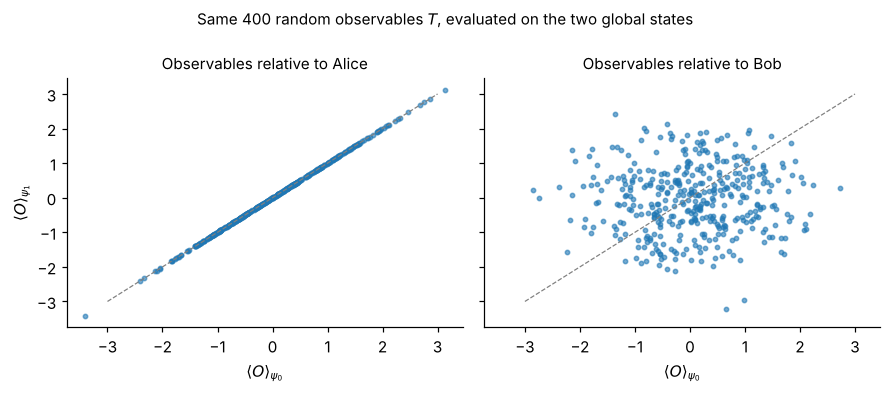

In [4]:
def relational_obs(T, frame):
    """Phi^{frame}(T) for T acting on the other two qubits (kept in A,B,C order):
       sum_i |i><i|_frame (x) (X(x)X)^i T (X(x)X)^i, embedded back into the A,B,C ordering."""
    op = np.kron(P0, T) + np.kron(P1, XX @ T @ XX)       # ordering (frame, rest1, rest2)
    order = [frame] + [q for q in range(3) if q != frame]
    t = op.reshape([2] * 6)
    perm = [order.index(q) for q in range(3)]
    return t.transpose(perm + [3 + p for p in perm]).reshape(8, 8)

rng = np.random.default_rng(0)
T = rand_herm(4, rng)
check("Phi^A(T) is invariant under the global Z2 action", np.allclose(CHARGE @ relational_obs(T, A) @ CHARGE, relational_obs(T, A)))
check("Phi^B(T) is invariant under the global Z2 action", np.allclose(CHARGE @ relational_obs(T, B) @ CHARGE, relational_obs(T, B)))

# Eqs. (A3), (A5): relative observable on the global state == plain observable on the relative state
for name, psi, psiA, psiB in [("psi0", psi0, psiA0, psiB0), ("psi1", psi1, psiA1, psiB1)]:
    check(f"Eq. (A3) for {name}", np.isclose(expval(psi, relational_obs(T, A)), expval(psiA, T)))
    check(f"Eq. (A5) for {name}", np.isclose(expval(psi, relational_obs(T, B)), expval(psiB, T)))

# Many random observables: what can each frame see?
Ts = [rand_herm(4, rng) for _ in range(400)]
eA = np.array([[expval(p, relational_obs(t, A)) for p in (psi0, psi1)] for t in Ts])
eB = np.array([[expval(p, relational_obs(t, B)) for p in (psi0, psi1)] for t in Ts])
dA, dB = np.abs(eA[:, 0] - eA[:, 1]).max(), np.abs(eB[:, 0] - eB[:, 1]).max()
print(f"max |<O>_psi0 - <O>_psi1| over 400 random observables:  relative to A = {dA:.2e},  relative to B = {dB:.3f}")
check("no observable relative to Alice separates psi0 from psi1", dA < 1e-12)
check("some observable relative to Bob separates psi0 from psi1", dB > 0.5)

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.6), sharex=True, sharey=True)
for ax, e, ttl in [(axes[0], eA, "Observables relative to Alice"), (axes[1], eB, "Observables relative to Bob")]:
    ax.plot([-3, 3], [-3, 3], color="grey", lw=0.8, ls="--")
    ax.scatter(e[:, 0], e[:, 1], s=8, alpha=0.6)
    ax.set_title(ttl, fontsize=10)
    ax.set_xlabel(r"$\langle O\rangle_{\psi_0}$")
axes[0].set_ylabel(r"$\langle O\rangle_{\psi_1}$")
fig.suptitle("Same 400 random observables $T$, evaluated on the two global states", fontsize=10)
fig.tight_layout(); plt.show()

report('§2 relative observables')

## 3. The charge observable, and the two twirls

$G=X_A\otimes X_B\otimes X_C$ has expectation $+1$ on $\psi_0$ and $-1$ on $\psi_1$. It is invariant under the group action but is **not** of the form $\Phi^A_{BC}(T)$, so it carries information absent from Alice's relative description (Eq. A9).

The same example shows the physical difference between the two group averages. Take the coherent superposition $|\phi\rangle=(|\psi_0\rangle+|\psi_1\rangle)/\sqrt2$.

* As a density operator it is **not** invariant. Taken at face value, Bob would see the product state $|01\rangle$.
* The incoherent twirl $\mathcal G$ turns it into the equal mixture of $\psi_0$ and $\psi_1$, and Bob's relative state is then exactly $\bar\rho^B_{AC}$ of Eq. (31). The "equal probability" assignment in the operational section therefore corresponds to a concrete physical operation (ignorance of which group element was applied).
* The coherent average $\Pi_0$ is a post-selection and returns $\psi_0$.

In [5]:
print("<X(x)X(x)X>  psi0 :", expval(psi0, CHARGE), "   psi1 :", expval(psi1, CHARGE))
check("charge separates the global states", expval(psi0, CHARGE) > 0.99 and expval(psi1, CHARGE) < -0.99)

# Is the charge a relative observable?  If it were Phi^A(T) for some T, it would be determined by its A=0 block.
blockA0 = CHARGE.reshape(2, 4, 2, 4)[0, :, 0, :]                    # <0|_A G |0>_A  (4 x 4)
check("charge is NOT of the form Phi^A(T)  (would have to equal Phi^A(<0|G|0>))",
      not np.allclose(CHARGE, relational_obs(blockA0, A)))
print("   (<0|_A G |0>_A = 0 here, so the only candidate is T = 0, which gives Phi^A(0) = 0 != G)")

# Coherent vs incoherent group averaging
phi = (psi0 + psi1) / np.sqrt(2)                     # a coherent superposition of the two charge sectors
rho_phi = outer(phi)
check("|phi> = (psi0+psi1)/sqrt2 is NOT an invariant state", not np.allclose(CHARGE @ rho_phi @ CHARGE, rho_phi))
print("\nAlice's view of |phi>      :", reduce_frame(phi, A))
print("Bob's view of |phi> (pure):", reduce_frame(phi, B), " <- |01>, a product state")
rho_tw = twirl(rho_phi)
check("incoherent twirl of |phi><phi| is the 50/50 mixture of psi0 and psi1",
      np.allclose(rho_tw, 0.5 * (outer(psi0) + outer(psi1))))
rho_bar = 0.5 * (outer(psiB0) + outer(psiB1))
check("Bob's relative state of the twirled state is exactly rho_bar of Eq. (31)",
      np.allclose(reduce_frame_dm(rho_tw, B), rho_bar))
check("coherent twirl Pi_0|phi> (renormalised) recovers psi0",
      np.allclose(coherent_twirl(phi) / np.linalg.norm(coherent_twirl(phi)), psi0))

report('§3 charge and twirls')

<X(x)X(x)X>  psi0 : 1.0    psi1 : -1.0
   (<0|_A G |0>_A = 0 here, so the only candidate is T = 0, which gives Phi^A(0) = 0 != G)

Alice's view of |phi>      : [ 0.+0.j  1.+0.j  0.+0.j -1.+0.j]
Bob's view of |phi> (pure): [0.+0.j 1.+0.j 0.+0.j 0.+0.j]  <- |01>, a product state
[§3 charge and twirls] 6/6 checks passed


## 4. Extra-particle change of frame, implemented directly

The paper describes the map in Eqs. (24)–(27). Here I build it explicitly.

* **Disentangler.** $T^A=|0\rangle\langle0|_A\otimes I\otimes I+|1\rangle\langle1|_A\otimes X_B\otimes X_C$. On $\psi_0$ it gives $|+\rangle_A\otimes\psi^A_{BC}$ and on $\psi_1$ it gives $|-\rangle_A\otimes\psi^A_{BC}$, so the frame qubit itself carries the charge: the "extra particle".
* **Controlled unitaries.** With $U_\pm=|0\rangle\langle0|\otimes I\pm|1\rangle\langle1|\otimes X$ acting on $(B|A,\,C|A)\to(A|B,\,C|B)$, define $S_{A\to B}=|+\rangle\langle+|_E\otimes U_++|-\rangle\langle-|_E\otimes U_-$, where $E$ is the extra particle. In the paper's Eq. (26) the control projectors on the extra particle are written $|0\rangle\langle0|$ and $|1\rangle\langle1|$ (trivial and sign irrep). Here I write the two charge eigenstates of the extra particle, the states $|\pm\rangle$ produced by $T^A$, as $|+\rangle$ and $|-\rangle$; the two labellings describe the same control. The construction reproduces Eqs. (16) and (17).
* **Consistency.** The change of frame should be "undo Alice's disentangler, apply Bob's", $S_{A\to B}=\mathrm{SWAP}\cdot T^B(T^A)^\dagger$. I check this identity, and also (numerically, as a test and not a proof) that $S_{A\to B}$ maps $T^A\rho T^{A\dagger}$ to $T^B\rho T^{B\dagger}$ for 50 random invariant mixed states, not only for $\psi_0,\psi_1$.

In [6]:
def disentangler(frame):
    """T^{frame}: |0><0|_frame (x) I (x) I + |1><1|_frame (x) X (x) X, Eq. (27) generalised to any frame."""
    op = np.kron(P0, np.eye(4)) + np.kron(P1, XX)
    order = [frame] + [q for q in range(3) if q != frame]
    t = op.reshape([2] * 6)
    perm = [order.index(q) for q in range(3)]
    return t.transpose(perm + [3 + p for p in perm]).reshape(8, 8)

TA, TB = disentangler(A), disentangler(B)
check("T^A and T^B are unitary", np.allclose(TA @ TA.conj().T, np.eye(8)) and np.allclose(TB @ TB.conj().T, np.eye(8)))

# T^A sends the frame qubit to |+> or |->  -- this is the 'extra particle' carrying the charge
check("T^A psi0 = |+>_A (x) (BC state relative to A)", np.allclose(TA @ psi0, np.kron(KETP, psiA0)))
check("T^A psi1 = |->_A (x) (BC state relative to A)", np.allclose(TA @ psi1, np.kron(KETM, psiA1)))

# Eqs. (24)-(26): controlled unitaries acting on (B|A, C|A) -> (A|B, C|B), controlled on the extra particle
Uplus  = np.kron(P0, I2) + np.kron(P1, X)
Uminus = np.kron(P0, I2) - np.kron(P1, X)
S_AB = np.kron(outer(KETP), Uplus) + np.kron(outer(KETM), Uminus)     # Eq. (26), acting on (extra particle, x, y)
check("S_{A->B} is unitary", np.allclose(S_AB @ S_AB.conj().T, np.eye(8)))

chi = psiA0                                                            # Alice's relative state (same for both)
check("S_{A->B} maps |+> (x) chi_A to |+> (x) psi0^B  (charge +)", np.allclose(S_AB @ np.kron(KETP, chi), np.kron(KETP, psiB0)))
check("S_{A->B} maps |-> (x) chi_A to |-> (x) psi1^B  (charge -)", np.allclose(S_AB @ np.kron(KETM, chi), np.kron(KETM, psiB1)))

# S_{A->B} should equal  T^B (T^A)^dagger  up to relabelling the extra-particle slot (qubit 0 <-> qubit 1)
SWAP01 = np.eye(8).reshape(2, 2, 2, 2, 2, 2).transpose(1, 0, 2, 3, 4, 5).reshape(8, 8)
check("S_{A->B} = SWAP . T^B (T^A)^dagger  (the change of frame is 'undo A's disentangler, apply B's')",
      np.allclose(S_AB, SWAP01 @ TB @ TA.conj().T))

# Tested on random invariant (mixed, both charge sectors) states, not only on psi0 and psi1
rng = np.random.default_rng(11)
errs = []
for _ in range(50):
    rho = rand_invariant_state(rng)
    lhs = S_AB @ (TA @ rho @ TA.conj().T) @ S_AB.conj().T
    rhs = SWAP01 @ (TB @ rho @ TB.conj().T) @ SWAP01.T
    errs.append(np.abs(lhs - rhs).max())
check(f"S_(A->B) (T^A rho T^A^dag) S^dag = T^B rho T^B^dag for 50 random invariant states (max err {max(errs):.1e})", max(errs) < 1e-12)

# Relation to the perspective-neutral map: S restricted to charge + equals U_+, which is V on H_0 up to the |+> label
check("U_+ equals the perspective-neutral change of frame on H_0", np.allclose(Uplus, V_pn))
check("U_- equals the sector-restricted analogue V^(1) on H_1", np.allclose(Uminus, V_sg))

report('§4 extra-particle map')

[§4 extra-particle map] 10/10 checks passed


## 5. The operational description

Alice's accessible framed observables are $|i\rangle\langle i|_A\otimes T_C$. They give identical statistics for $\psi_0^B$ and $\psi_1^B$, so she identifies the two Bob-relative states and the natural representative is the mixture $\bar\rho=\tfrac12(|01\rangle\langle01|+|10\rangle\langle10|)$, Eq. (31).

At the level of equivalence classes the change of frame is the map $Q$ of Eq. (B12), applied to the dephased relative states $\bar\rho=D(R\rho R^\dagger)$. The checks below go beyond the two example states: for 100 random invariant mixed states (random density matrices passed through the twirl) I verify $Q(\bar\rho^A)=\bar\rho^B$, that the *same formula run backwards* is the inverse, and that $D$ is idempotent. The last block checks the Appendix B states.

*Note on Eqs. (B19)–(B20).* My calculation gives $\tfrac12(|0\rangle\langle0|_A\otimes|1\rangle\langle1|_C+|1\rangle\langle1|_A\otimes|0\rangle\langle0|_C)$ for both. In the published PDF the second term is also printed with $|1\rangle\langle1|_C$. This looks like a small typographical slip (as printed, $C=1$ with certainty, which is inconsistent with Eq. (31)); it does not affect any result of the paper.

In [7]:
# --- (i) Alice cannot tell the two Bob-relative states apart by framed observables |i><i|_A (x) T_C
rho_B0, rho_B1 = outer(psiB0), outer(psiB1)
rng = np.random.default_rng(5)
gap = max(abs(expval(rho_B0, np.kron(PROJ[i], Tc)) - expval(rho_B1, np.kron(PROJ[i], Tc)))
          for i in (0, 1) for Tc in [rand_herm(2, rng) for _ in range(200)])
check(f"framed observables |i><i|_A (x) T_C cannot separate psi0^B from psi1^B (max gap {gap:.1e})", gap < 1e-12)
check("equal-weight mixture equals (|01><01| + |10><10|)/2, Eq. (31)",
      np.allclose(rho_bar, 0.5 * (outer(np.eye(4)[1]) + outer(np.eye(4)[2]))))

# --- (ii) frame reduction D and the change-of-frame map Q, Eqs. (B10)-(B16)
def dephase(rho):
    """D: rho_{FC} -> sum_k |k><k|_F (x) <k|rho|k>_F   (F = first qubit of the pair)."""
    return sum(np.kron(P, I2) @ rho @ np.kron(P, I2) for P in PROJ)

def Q(rho):
    """Eq. (B12)/(B15): sum_i |i><i|_new (x) <i|_old X_C^i rho X_C^i |i>_old, on (frame, C) ordering."""
    out = np.zeros((4, 4), dtype=complex)
    for i in (0, 1):
        Xc = np.kron(I2, X) if i else np.eye(4)
        blk = (Xc @ rho @ Xc)[2 * i:2 * i + 2, 2 * i:2 * i + 2]       # <i|_old (...) |i>_old
        out += np.kron(PROJ[i], blk)
    return out

rbarA = lambda rho: dephase(reduce_frame_dm(rho, A))     # rho-bar^A_{BC}
rbarB = lambda rho: dephase(reduce_frame_dm(rho, B))     # rho-bar^B_{AC}

rng = np.random.default_rng(21)
e_map, e_inv, e_idem = [], [], []
for _ in range(100):
    rho = rand_invariant_state(rng)
    a, b = rbarA(rho), rbarB(rho)
    e_map.append(np.abs(Q(a) - b).max())            # Q: A-frame description -> B-frame description
    e_inv.append(np.abs(Q(b) - a).max())            # the same formula run backwards is the inverse
    e_idem.append(np.abs(dephase(a) - a).max())     # D is idempotent
check(f"Q(rho-bar^A) = rho-bar^B on 100 random invariant states (max err {max(e_map):.1e})", max(e_map) < 1e-12)
check(f"Q is its own inverse on framed states: Q(rho-bar^B) = rho-bar^A (max err {max(e_inv):.1e})", max(e_inv) < 1e-12)
check("the frame reduction D is idempotent", max(e_idem) < 1e-12)

# --- (iii) the two global states collapse to ONE operational state: information has been discarded
check("rho-bar^A(psi0) = rho-bar^A(psi1)", np.allclose(rbarA(outer(psi0)), rbarA(outer(psi1))))
check("rho-bar^B(psi0) = rho-bar^B(psi1)", np.allclose(rbarB(outer(psi0)), rbarB(outer(psi1))))
check("... and rho-bar^B(psi0) equals the mixture rho_bar of Eq. (31)", np.allclose(rbarB(outer(psi0)), rho_bar))

# --- (iv) check of Appendix B, Eqs. (B18)-(B20)
Pb = lambda i, j: np.kron(PROJ[i], PROJ[j])       # |i><i| (x) |j><j|
check("Eq. (B18):  rho-bar^A = (|0><0|_B (x) |1><1|_C + |1><1|_B (x) |1><1|_C)/2", np.allclose(rbarA(outer(psi0)), 0.5 * (Pb(0, 1) + Pb(1, 1))))
check("my result for (B19)/(B20):  (|0><0|_A (x) |1><1|_C + |1><1|_A (x) |0><0|_C)/2", np.allclose(rbarB(outer(psi0)), 0.5 * (Pb(0, 1) + Pb(1, 0))))
check("... which differs from the second term as printed in (B19)/(B20) in the published PDF (|1><1|_C twice)",
      not np.allclose(rbarB(outer(psi0)), 0.5 * (Pb(0, 1) + Pb(1, 1))))

report('§5 operational')

[§5 operational] 11/11 checks passed


## 6. Algebra-level check of Table I and Appendix C

Table I summarises the three approaches by which global states they allow and whether Alice can distinguish them. This can be tested by computing dimensions of operator algebras directly.

* The invariant algebra $\mathcal B(\mathcal H_{ABC})^G=\mathcal B(\mathcal H_0)\oplus\mathcal B(\mathcal H_1)$ has dimension $16+16=32$.
* **Operational:** Alice's relative algebra $\Phi^A(\mathcal B(\mathcal H_{BC}))$ has dimension 16, a strict subalgebra. She cannot distinguish all invariant states.
* **Extra-particle:** adding the charge $G$ gives the full 32-dimensional algebra, so she can.
* **Perspective-neutral:** restricted to $\mathcal H_0$, her algebra is all of $\mathcal B(\mathcal H_0)$ (dimension 16), so she can.

For Appendix C I compute $\dim\bigl(\Phi^A(\mathcal B(BC))\cap\Phi^B(\mathcal B(AC))\bigr)$ as $\dim\Phi^A+\dim\Phi^B-\dim(\Phi^A+\Phi^B)$ and compare it with the framed observables.

In [8]:
def span_basis(mats, tol=1e-9):
    """Orthonormal basis of the linear span of a list of matrices."""
    M = np.array([m.flatten() for m in mats])
    _, s, vh = np.linalg.svd(M, full_matrices=False)
    return [vh[i].reshape(mats[0].shape) for i in range((s > tol).sum())]

def generated_algebra_dim(ops, tol=1e-9):
    """Dimension of the unital *-algebra generated by `ops` (iterate: add products and adjoints until stable)."""
    d = ops[0].shape[0]
    Bs = span_basis(list(ops) + [np.eye(d, dtype=complex)], tol)
    while True:
        new = span_basis(Bs + [a @ b for a in Bs for b in Bs] + [a.conj().T for a in Bs], tol)
        if len(new) == len(Bs):
            return len(Bs)
        Bs = new

def matrix_units(n):
    out = []
    for i in range(n):
        for j in range(n):
            E = np.zeros((n, n), dtype=complex); E[i, j] = 1; out.append(E)
    return out

E4 = matrix_units(4)
PhiA = [relational_obs(E, A) for E in E4]          # Phi^A(B(H_BC)),  a 16-dim set
PhiB = [relational_obs(E, B) for E in E4]          # Phi^B(B(H_AC))

# invariant algebra = commutant of the generator: dimension of the null space of X -> [G, X] on 8x8 matrices
comm = np.array([(CHARGE @ E - E @ CHARGE).flatten() for E in matrix_units(8)]).T
dim_inv = 64 - np.linalg.matrix_rank(comm)                    # should be 4^2 + 4^2 = 32
print("dim of invariant algebra B(H_ABC)^G           :", dim_inv, "(= 4^2 + 4^2)")
dimA = len(span_basis(PhiA))
dimA_plus_charge = generated_algebra_dim(PhiA + [CHARGE])
print("dim of Alice's relative algebra  Phi^A(B(BC))  :", dimA)
print("dim of algebra generated by Phi^A and G        :", dimA_plus_charge)

# restriction to the physical subspace H_0 (perspective-neutral)
dimA_H0 = len(span_basis([PI[+1] @ P @ PI[+1] for P in PhiA]))
print("dim of Alice's algebra restricted to H_0       :", dimA_H0, "(= dim B(H_0) = 16)")

check("operational: Alice's relative algebra is a strict subalgebra of the invariant algebra (16 < 32)", dimA == 16 < dim_inv == 32)
check("extra-particle: adding the charge G makes Alice's algebra the full invariant algebra (32)", dimA_plus_charge == 32)
check("perspective-neutral: restricted to H_0, Alice's algebra is all of B(H_0)", dimA_H0 == 16)
check("Alice's algebra is closed under multiplication already (Phi^A is a homomorphism)", generated_algebra_dim(PhiA) == 16)

# Appendix C: observables accessible to BOTH frames
dimB = len(span_basis(PhiB))
dim_sum = len(span_basis(PhiA + PhiB))
dim_intersection = dimA + dimB - dim_sum
# framed observables sum_i |i><i|_B (x) C_i with arbitrary C_0, C_1: take C_i over matrix units, one i at a time
FA = [relational_obs(np.kron(PROJ[i], Ci), A) for i in (0, 1) for Ci in matrix_units(2)]
dimF = len(span_basis(FA))
inside_B = len(span_basis(PhiB + FA)) == dimB                      # F^A_{C|B} is contained in Phi^B(B(AC))
print(f"\ndim Phi^A = {dimA}, dim Phi^B = {dimB}, dim(Phi^A + Phi^B) = {dim_sum}  =>  dim(intersection) = {dim_intersection}")
print(f"dim of framed observables F^A_(C|B) = {dimF}")
check("Appendix C: observables accessible to both Alice and Bob form an 8-dimensional space", dim_intersection == 8)
check("Appendix C: ... and it equals the framed observables F^A_(C|B) = F^B_(C|A)", dimF == 8 and inside_B)

report('§6 algebras')

dim of invariant algebra B(H_ABC)^G           : 32 (= 4^2 + 4^2)
dim of Alice's relative algebra  Phi^A(B(BC))  : 16
dim of algebra generated by Phi^A and G        : 32
dim of Alice's algebra restricted to H_0       : 16 (= dim B(H_0) = 16)

dim Phi^A = 16, dim Phi^B = 16, dim(Phi^A + Phi^B) = 24  =>  dim(intersection) = 8
dim of framed observables F^A_(C|B) = 8
[§6 algebras] 6/6 checks passed


## 7. Extending the example to $\mathbb{Z}_N$

*Exploratory.* Replace the $\mathbb{Z}_2$ shift by a cyclic shift of order $N$. Let $S|j\rangle=|j+1\rangle$, $\omega=e^{2\pi i/N}$, $U=S\otimes S\otimes S$. Starting from an arbitrary Alice-relative state $|\phi\rangle_{BC}$ define
$$|\Psi_q\rangle=\frac1{\sqrt N}\sum_{g=0}^{N-1}\omega^{-qg}\,|g\rangle_A\otimes(S^g\otimes S^g)|\phi\rangle_{BC}.$$
Then $U|\Psi_q\rangle=\omega^q|\Psi_q\rangle$ and $R_{0|A}|\Psi_q\rangle=|\phi\rangle$ for every $q$: Alice's description is independent of the charge. For Bob,
$$|\Psi_q\rangle^B=(Z_A^{-q}\otimes I_C)|\Psi_0\rangle^B,\qquad \langle\Psi_p^B|\Psi_q^B\rangle=\operatorname{Tr}(\rho_A Z^{p-q}),$$
with $Z=\operatorname{diag}(1,\omega,\dots,\omega^{N-1})$ and $\rho_A$ the reduced state of $|\Psi_0\rangle^B$ on $A$.

The $N$ Bob-relative states are mutually orthogonal exactly when the diagonal of $\rho_A$ is uniform (the Fourier transform of the diagonal vanishes at all nonzero frequencies). The $\mathbb{Z}_2$ example is a special case; for a generic $|\phi\rangle$ they are not orthogonal.

[§7 Z_N] 6/6 checks passed


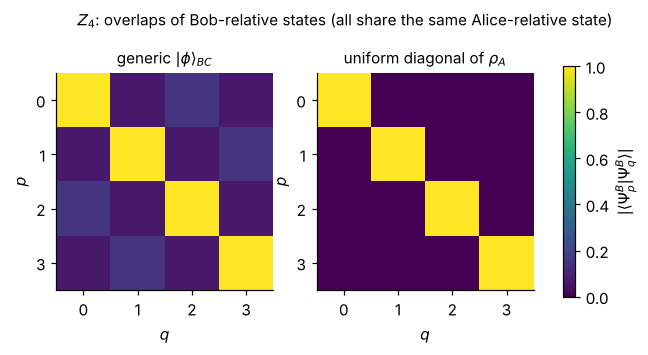

In [9]:
def zn_states(N, phi):
    """Global charge eigenstates |Psi_q>, q = 0..N-1, all sharing the Alice-relative state phi (N x N array on B,C).
       Returns the list of global states (N,N,N arrays) and the Bob-relative states <0|_B |Psi_q> sqrt(N) (N x N, indices a,c)."""
    omega = np.exp(2j * np.pi / N)
    glob, bob = [], []
    for q in range(N):
        psi = np.zeros((N, N, N), dtype=complex)
        for g in range(N):
            psi[g] = omega ** (-q * g) * np.roll(np.roll(phi, g, axis=0), g, axis=1) / np.sqrt(N)
        glob.append(psi)
        bob.append(np.sqrt(N) * psi[:, 0, :])
    return glob, bob

def zn_phi_from_bob0(v):
    """Inverse construction: the Alice-relative state phi that makes Bob's q=0 state equal to v[a,c]."""
    N = v.shape[0]
    phi = np.zeros((N, N), dtype=complex)
    for a in range(N):
        for c in range(N):
            phi[(-a) % N, (c - a) % N] = v[a, c]
    return phi

rng = np.random.default_rng(1)
for N in (2, 3, 4, 5):
    omega = np.exp(2j * np.pi / N)
    Zk = lambda k: np.diag(omega ** (k * np.arange(N)))
    S_shift = np.roll(np.eye(N), 1, axis=0)
    phi = rng.normal(size=(N, N)) + 1j * rng.normal(size=(N, N)); phi /= np.linalg.norm(phi)
    glob, bob = zn_states(N, phi)
    same_alice = all(np.allclose(np.sqrt(N) * g[0], phi) for g in glob)
    eig = all(np.allclose(np.einsum('ai,bj,ck,ijk->abc', S_shift, S_shift, S_shift, glob[q]), omega ** q * glob[q]) for q in range(N))
    twist = all(np.allclose(bob[q], Zk(-q) @ bob[0]) for q in range(N))
    rhoA = bob[0] @ bob[0].conj().T
    ovl = all(np.isclose(np.vdot(bob[p], bob[q]), np.trace(rhoA @ Zk(p - q))) for p in range(N) for q in range(N))
    check(f"Z_{N}: same Alice state for all q | U Psi_q = w^q Psi_q | Bob twist Z^-q | overlap = Tr[rho_A Z^(p-q)]",
          same_alice and eig and twist and ovl)

# Orthogonality criterion: Bob's N states are mutually orthogonal  <=>  rho_A has uniform diagonal
N = 4
rng = np.random.default_rng(2)
phi_rand = rng.normal(size=(N, N)) + 1j * rng.normal(size=(N, N)); phi_rand /= np.linalg.norm(phi_rand)
v_unif = np.zeros((N, N), dtype=complex)
for a in range(N):
    v_unif[a, a] = 1 / np.sqrt(N)                      # Bob_0[a,c] = delta_{ac}/sqrt(N): uniform marginal on A
phi_unif = zn_phi_from_bob0(v_unif)

def overlap_matrix(phi):
    _, bob = zn_states(phi.shape[0], phi)
    return np.array([[abs(np.vdot(bob[p], bob[q])) for q in range(len(bob))] for p in range(len(bob))])

Gr, Gu = overlap_matrix(phi_rand), overlap_matrix(phi_unif)
check("uniform diagonal of rho_A  =>  Bob's 4 states are mutually orthogonal", np.allclose(Gu, np.eye(N)))
check("generic phi  =>  Bob's states are NOT mutually orthogonal", np.abs(Gr - np.eye(N)).max() > 0.05)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
for ax, M, ttl in [(axes[0], Gr, "generic $|\\phi\\rangle_{BC}$"), (axes[1], Gu, "uniform diagonal of $\\rho_A$")]:
    im = ax.imshow(M, vmin=0, vmax=1, cmap="viridis"); ax.set_title(ttl, fontsize=10)
    ax.set_xlabel("$q$"); ax.set_ylabel("$p$"); ax.set_xticks(range(N)); ax.set_yticks(range(N))
fig.colorbar(im, ax=axes, shrink=0.85, label=r"$|\langle\Psi_p^B|\Psi_q^B\rangle|$")
fig.suptitle(r"$Z_4$: overlaps of Bob-relative states (all share the same Alice-relative state)", fontsize=10)
plt.show()

report('§7 Z_N')

## 8. A non-ideal $U(1)$ frame

This section reproduces Example 5 of Garmier, Hausmann and Castro-Ruiz, *The Perspectives of Non-Ideal Quantum Reference Frames* (arXiv:2512.19343). The orientation POVM and relationalisation map are
$$\gamma_F(\theta)=\frac{|\theta\rangle\langle\theta|}{2\pi},\quad|\theta\rangle=\sum_{r\in\sigma_F}e^{ir\theta}|r\rangle,\qquad R_F(f)=\int d\theta\,\gamma_F(\theta)\otimes U_S(\theta)fU_S(\theta)^\dagger .$$
For integer spectra the integrand is a trigonometric polynomial of degree at most $\mathrm{spread}(\sigma_F)+\mathrm{spread}(\sigma_S)$, so a uniform $K$-point rule is exact once $K$ exceeds that degree; the code asserts this.

The preprint organises the Hilbert space by $\kappa(r)=\sigma_S\cap(r-\sigma_F)$. The generated algebra has dimension $\sum|\kappa|^2$ over the distinct non-empty $\kappa$-sets, which gives 6 and 7 for the two frame/system choices below. I check this against an explicit generation of the algebra. I also check that a relative phase in the frame state is invisible to single relational operators but visible in products of them (restricted to Hermitian operators).

In [10]:
def frame_povm(specF, K):
    """Orientation POVM gamma_F(theta) = |theta><theta| / 2 pi on a K-point grid."""
    spec = np.array(specF)
    thetas = 2 * np.pi * np.arange(K) / K
    return thetas, [np.outer(np.exp(1j * spec * t), np.exp(-1j * spec * t)) / (2 * np.pi) for t in thetas]

def U_sys(spec, t):
    return np.diag(np.exp(1j * np.array(spec) * t))

def relational_ops(specF, specS, K=32):
    """R_F(E_ij) for all matrix units E_ij of the system, in the ordering F (x) S.
       Integer spectra => the integrand is a trigonometric polynomial of degree <= spread_F + spread_S,
       so the uniform K-point rule is exact as long as K exceeds that degree (asserted below)."""
    assert K > (max(specF) - min(specF)) + (max(specS) - min(specS)), "grid too coarse for exact integration"
    thetas, gam = frame_povm(specF, K)
    wq, dS = 2 * np.pi / K, len(specS)
    ops = []
    for i in range(dS):
        for j in range(dS):
            E = np.zeros((dS, dS), dtype=complex); E[i, j] = 1
            ops.append(sum(wq * np.kron(gam[k], U_sys(specS, t) @ E @ U_sys(specS, t).conj().T) for k, t in enumerate(thetas)))
    return ops

def kappa_sets(specF, specS):
    """kappa(r) = sigma_S  intersect  (r - sigma_F) for every total charge r. Returns {r: frozenset}."""
    rs = sorted({a + b for a in specF for b in specS})
    return {r: frozenset(set(specS) & {r - a for a in specF}) for r in rs}

def kappa_dim(specF, specS):
    sectors = {k for k in kappa_sets(specF, specS).values() if k}
    return sum(len(k) ** 2 for k in sectors)

sA, sB = [-1, 0, 1], [-1, 1]
opsA, opsB = relational_ops(sA, sB), relational_ops(sB, sA)       # frame A (C^3) / system B (C^2),  and vice versa
print("frame A=C^3 observing B=C^2 :  image dim", len(span_basis(opsA)), "| generated algebra dim", generated_algebra_dim(opsA))
print("frame B=C^2 observing A=C^3 :  image dim", len(span_basis(opsB)), "| generated algebra dim", generated_algebra_dim(opsB))
check("generated algebra dimensions are 6 (> 4) and 7 (< 9), as stated in the preprint",
      generated_algebra_dim(opsA) == 6 and generated_algebra_dim(opsB) == 7)
check("kappa-set counting reproduces 6 and 7", kappa_dim(sA, sB) == 6 and kappa_dim(sB, sA) == 7)

# A relative phase in the frame state: invisible to single relational operators, visible in products
sig = np.diag([0.5, 0.5])
def state_phi(phi):
    ket = lambda t: np.exp(1j * np.array(sA) * t)
    v = (ket(0.0) + np.exp(1j * phi) * ket(2 * np.pi / 3)) / np.sqrt(2)
    v = v / np.linalg.norm(v)
    return np.kron(outer(v), sig)

H1 = [(o + o.conj().T) / 2 for o in opsA] + [1j * (o - o.conj().T) / 2 for o in opsA]     # Hermitian single operators
herm_parts = lambda a, b: [(a @ b + b @ a) / 2, 1j * (a @ b - b @ a) / 2]
prodH = [h for a in H1 for b in H1 for h in herm_parts(a, b)]
phis = np.linspace(0, 2 * np.pi, 7)
ref = state_phi(0)
spread1 = max(abs(np.trace(state_phi(p) @ o) - np.trace(ref @ o)) for p in phis for o in H1)
spread2 = max(abs(np.trace(state_phi(p) @ o) - np.trace(ref @ o)) for p in phis for o in prodH)
print(f"phi-dependence, single relational operators : {spread1:.1e}\nphi-dependence, Hermitian parts of products : {spread2:.3f}")
check("hidden relative phase invisible to single relational operators", spread1 < 1e-12)
check("hidden relative phase visible in products of relational operators", spread2 > 1e-2)

report('§8 U(1) frame')

frame A=C^3 observing B=C^2 :  image dim 4 | generated algebra dim 6
frame B=C^2 observing A=C^3 :  image dim 5 | generated algebra dim 7
phi-dependence, single relational operators : 1.1e-16
phi-dependence, Hermitian parts of products : 0.083
[§8 U(1) frame] 4/4 checks passed


## 9. State discrimination in the $\mathbb{Z}_2$ example

*Exploratory, and mainly a restatement.* Suppose Alice assigns priors $(p_0,p_1)$ to the two charge sectors, as classical uncertainty about which state was prepared. Because the Alice-relative states are identical, every measurement relative to her has $P(y|q=0)=P(y|q=1)$, so Bayes' rule leaves her posterior equal to her prior. The trace distances are $D(\rho_0^A,\rho_1^A)=0$ and $D(\rho_0^B,\rho_1^B)=1$. The Helstrom success probability is
$$P_{\rm succ}=\tfrac12\bigl(1+\|p_0\rho_0-p_1\rho_1\|_1\bigr),$$
which equals $\max(p_0,p_1)$ for Alice and $1$ for Bob; the entropy of Bob's mixture is the binary entropy $H(p_0)$. This puts Eq. (31) in the language of state discrimination; it does not add a new distinction in this example, since Alice's relative states are identical by construction.

trace distance:  Alice 0.0 |  Bob 1.0000000000000002
[§9 discrimination] 5/5 checks passed


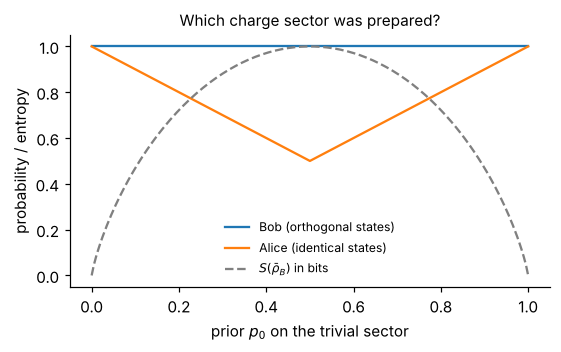

In [11]:
def helstrom(p0, r0, r1):
    return 0.5 * (1 + trace_norm(p0 * r0 - (1 - p0) * r1))

rA0, rA1, rB0_, rB1_ = outer(psiA0), outer(psiA1), outer(psiB0), outer(psiB1)
print("trace distance:  Alice", 0.5 * trace_norm(rA0 - rA1), "|  Bob", 0.5 * trace_norm(rB0_ - rB1_))

# (1) Alice's posterior equals her prior for every relative measurement
rng = np.random.default_rng(3)
_, vecs = np.linalg.eigh(relational_obs(rand_herm(4, rng), A))                 # projective measurement relative to A
like = lambda psi: np.array([abs(np.vdot(vecs[:, i], psi)) ** 2 for i in range(8)])
check("P(y|q=0) = P(y|q=1) for every outcome of a random measurement relative to Alice", np.allclose(like(psi0), like(psi1)))
check("... whereas the charge observable separates them perfectly", np.isclose(expval(psi0, PI[+1]), 1) and np.isclose(expval(psi1, PI[+1]), 0))

# (2) Helstrom success probability and entropy as functions of the prior
p = np.linspace(0, 1, 201)
succ_A = np.array([helstrom(x, rA0, rA1) for x in p])
succ_B = np.array([helstrom(x, rB0_, rB1_) for x in p])
def S_vn(x):
    ev_ = np.linalg.eigvalsh(x * rB0_ + (1 - x) * rB1_); ev_ = ev_[ev_ > 1e-12]
    return float(-(ev_ * np.log2(ev_)).sum())
H2 = np.array([S_vn(x) for x in p])
check("Alice's Helstrom success is max(p0, 1-p0): no better than guessing from the prior", np.allclose(succ_A, np.maximum(p, 1 - p)))
check("Bob's Helstrom success is 1 for every prior", np.allclose(succ_B, 1))
check("S(rho_B) equals the binary entropy H(p0) (orthogonal states)",
      np.allclose(H2[1:-1], -(p[1:-1] * np.log2(p[1:-1]) + (1 - p[1:-1]) * np.log2(1 - p[1:-1]))))

fig, ax = plt.subplots(figsize=(5.2, 3.3))
ax.plot(p, succ_B, label="Bob (orthogonal states)")
ax.plot(p, succ_A, label="Alice (identical states)")
ax.plot(p, H2, ls="--", color="grey", label=r"$S(\bar\rho_B)$ in bits")
ax.set_xlabel(r"prior $p_0$ on the trivial sector"); ax.set_ylabel("probability / entropy")
ax.legend(frameon=False, fontsize=8); ax.set_title("Which charge sector was prepared?", fontsize=10)
fig.tight_layout(); plt.show()

report('§9 discrimination')

## 10. Can a non-ideal frame resolve different sectors? (numerics)

*Exploratory.* The $U(1)$ example suggests distinguishing measurements generated by a **single** relational POVM from measurements in the **full algebra** those operators generate. With the dual map $R_F^*$ defined by $\operatorname{tr}[\rho R_F(m)]=\operatorname{tr}[R_F^*(\rho)\,m]$, optimising over system POVMs gives
$$D_{\rm single}(\rho,\rho')=\tfrac12\|R_F^*(\rho)-R_F^*(\rho')\|_1 .$$
I sample Haar-random pure states inside fixed total-charge subspaces and compare pairs from different $\kappa$-sectors (100 draws per pair; averages depend on the draws). I also test whether each sector projector lies in the generated algebra and in the span of the single relational operators.

In [12]:
def probe(specF, specS, K, nsamp=100, seed=7):
    """Numerical test of sector distinguishability for a non-ideal frame (see text)."""
    rg = np.random.default_rng(seed)
    ops = relational_ops(specF, specS, K)
    dS, dF = len(specS), len(specF)
    Bs = span_basis(ops + [np.eye(ops[0].shape[0], dtype=complex)])
    while True:
        new = span_basis(Bs + [a @ b for a in Bs for b in Bs] + [a.conj().T for a in Bs])
        if len(new) == len(Bs):
            break
        Bs = new
    def in_span(basis, M):
        Mat = np.array([b.flatten() for b in basis]).T
        c = np.linalg.lstsq(Mat, M.flatten(), rcond=None)[0]
        return np.linalg.norm(Mat @ c - M.flatten()) < 1e-8
    ch = (np.kron(np.diag(specF), np.eye(dS)) + np.kron(np.eye(dF), np.diag(specS))).diagonal().real   # total charge r
    rs = sorted(set(ch))
    Pi_r = {r: np.diag(np.isclose(ch, r).astype(float)) for r in rs}
    kap = {r: frozenset(set(specS) & {r - a for a in specF}) for r in rs}
    sectors = {}
    for r, k in kap.items():
        sectors.setdefault(k, []).append(r)
    SP = {k: sum(Pi_r[r] for r in rr) for k, rr in sectors.items()}
    alg_ok = all(in_span(Bs, P) for P in SP.values())
    single_flags = {tuple(float(x) for x in sorted(k)): bool(in_span(ops, P)) for k, P in SP.items()}
    def Rstar(rho):
        out = np.zeros((dS, dS), dtype=complex)
        for i in range(dS):
            for j in range(dS):
                out[j, i] = np.trace(rho @ ops[i * dS + j])
        return out
    def random_state(r):
        idx = np.where(np.isclose(ch, r))[0]
        v = np.zeros(len(ch), dtype=complex)
        v[idx] = rg.normal(size=len(idx)) + 1j * rg.normal(size=len(idx))
        return outer(v / np.linalg.norm(v))
    means = []
    for r1 in rs:
        for r2 in rs:
            if r1 < r2 and kap[r1] != kap[r2]:
                means.append(np.mean([0.5 * trace_norm(Rstar(random_state(r1)) - Rstar(random_state(r2))) for _ in range(nsamp)]))
    return alg_ok, single_flags, np.array(means)

EXAMPLES = [("frame {-1,0,1}, system {-1,1}   (preprint Ex. 5, A)", [-1, 0, 1], [-1, 1], 32),
            ("frame {-1,1}, system {-1,0,1}   (preprint Ex. 5, B)", [-1, 1], [-1, 0, 1], 32),
            ("frame {-3..3}, system {-1,1}", list(range(-3, 4)), [-1, 1], 64)]
for name, sF, sS, K in EXAMPLES:
    alg_ok, single_flags, means = probe(sF, sS, K)
    print(name)
    print("   kappa-sets by total charge:", {float(r): sorted(k) for r, k in kappa_sets(sF, sS).items()})
    print("   all sector projectors lie in the generated algebra:", alg_ok)
    print("   sector projector in span of single relational operators:", single_flags)
    print(f"   D_single over cross-sector pairs: mean of means {means.mean():.3f}, min {means.min():.3f}, share with mean>0.99: {(means > 0.99).mean():.2f}")
    check(f"{name.split('(')[0].strip()}: sector projectors in generated algebra", alg_ok)

report('§10 sector numerics')

frame {-1,0,1}, system {-1,1}   (preprint Ex. 5, A)
   kappa-sets by total charge: {-2.0: [-1], -1.0: [-1], 0.0: [-1, 1], 1.0: [1], 2.0: [1]}
   all sector projectors lie in the generated algebra: True
   sector projector in span of single relational operators: {(-1.0,): False, (-1.0, 1.0): False, (1.0,): False}
   D_single over cross-sector pairs: mean of means 0.832, min 0.649, share with mean>0.99: 0.50
frame {-1,1}, system {-1,0,1}   (preprint Ex. 5, B)
   kappa-sets by total charge: {-2.0: [-1], -1.0: [0], 0.0: [-1, 1], 1.0: [0], 2.0: [1]}
   all sector projectors lie in the generated algebra: True
   sector projector in span of single relational operators: {(-1.0,): False, (0.0,): True, (-1.0, 1.0): False, (1.0,): False}
   D_single over cross-sector pairs: mean of means 0.926, min 0.655, share with mean>0.99: 0.78
frame {-3..3}, system {-1,1}
   kappa-sets by total charge: {-4.0: [-1], -3.0: [-1], -2.0: [-1, 1], -1.0: [-1, 1], 0.0: [-1, 1], 1.0: [-1, 1], 2.0: [-1, 1], 3.0: [1], 

**What the numerics show**

* In all three examples the sector projectors lie in the generated algebra, so the full algebra distinguishes states from different $\kappa$-sectors.
* The span of single relational operators behaves differently in the two preprint examples. For frame A none of the sector projectors lies in the span; for frame B the projector onto the sector $\{0\}$ does.
* The random-state averages (about 0.83, 0.93, 0.72) show no clean trend with frame size, and the sets of sector pairs differ between examples. A simple "bigger frame, harder to distinguish" statement is not supported. The answer depends on *which* sectors are compared, which motivates the exact analysis in §11.

## 11. Sector distinguishability from the $\kappa$-sets

*Exploratory; I have not checked whether this is known.* For a pure global state of definite total charge $r$,
$$|\Psi\rangle=\sum_{a+s=r}c_{as}|a\rangle_F|s\rangle_S ,\qquad (\langle\theta|_F\otimes I_S)|\Psi\rangle=e^{-ir\theta}U_S(\theta)|\psi_S\rangle,$$
with the normalised effective system state $|\psi_S\rangle=\sum_{s\in\kappa(r)}c_{r-s,s}|s\rangle$ supported on $K(r)=\operatorname{span}\{|s\rangle:s\in\kappa(r)\}$. Substituting into $R_F$ gives $\operatorname{tr}[\rho R_F(m)]=\langle\psi_S|m|\psi_S\rangle$. So for fixed total charge, a single relational measurement is an ordinary system measurement on an effective pure state, and the optimal single-measurement distinguishability of two such hypotheses is $D=\sqrt{1-|\langle\psi_1|\psi_2\rangle|^2}$.

For two sectors with different $\kappa$-sets:

1. **Best case.** $D=1$ is attainable, since the sets differ and one contains a basis vector absent from the other.
2. **Worst case.** If the $\kappa$-sets overlap, both effective states can be chosen as the same basis vector, giving $D=0$. If they are disjoint, every pair of effective states is orthogonal and $D=1$.
3. **Full generated algebra.** Sector projectors separate states supported on different $\kappa$-sets. They do not separate total charges with the same $\kappa$-set.
4. **Span observation (numerical only).** In the examples, a sector projector lies in the span of single relational operators exactly when its $\kappa$-set is disjoint from all the others. I have not derived this in general.

The criterion for single relational measurements is therefore the *intersection of $\kappa$-sets*, not the size of the frame by itself. The code checks (a) the effective-state structure, (b) the extremal values on representative states and on random states, and (c) the span observation.

In [13]:
def verify_criterion(specF, specS, K, nsamp=200, seed=3):
    rg = np.random.default_rng(seed)
    ops = relational_ops(specF, specS, K)
    dS, dF = len(specS), len(specF)
    ch = (np.kron(np.diag(specF), np.eye(dS)) + np.kron(np.eye(dF), np.diag(specS))).diagonal().real
    rs = sorted(set(ch))
    kap = {r: frozenset(set(specS) & {r - a for a in specF}) for r in rs}
    def Rstar(rho):
        out = np.zeros((dS, dS), dtype=complex)
        for i in range(dS):
            for j in range(dS):
                out[j, i] = np.trace(rho @ ops[i * dS + j])
        return out
    def vec_in(r):
        idx = np.where(np.isclose(ch, r))[0]
        v = np.zeros(len(ch), dtype=complex)
        v[idx] = rg.normal(size=len(idx)) + 1j * rg.normal(size=len(idx))
        return v / np.linalg.norm(v)
    # (a) the effective system state is pure and supported on kappa(r)
    ok_a = True
    for r in rs:
        S_ = Rstar(outer(vec_in(r)))
        support = [j for j, sv in enumerate(specS) if sv in kap[r]]
        rest = [j for j in range(dS) if j not in support]
        off = S_[np.ix_(rest, rest)] if rest else np.zeros((1, 1))
        ok_a &= bool(abs(np.linalg.eigvalsh(S_)[-1] - 1) < 1e-8 and abs(off).max() < 1e-8)
    # (b) best/worst case for every pair of sectors with different kappa-sets
    ok_b, npairs = True, 0
    for r1 in rs:
        for r2 in rs:
            if r1 < r2 and kap[r1] != kap[r2]:
                npairs += 1
                Ds = [0.5 * trace_norm(Rstar(outer(vec_in(r1))) - Rstar(outer(vec_in(r2)))) for _ in range(nsamp)]
                common = kap[r1] & kap[r2]
                if common:                                           # overlapping kappa-sets: D = 0 is attainable
                    s0 = sorted(common)[0]
                    def basis_state(r):
                        v = np.zeros(len(ch), dtype=complex); v[specF.index(r - s0) * dS + specS.index(s0)] = 1; return v
                    d_worst = 0.5 * trace_norm(Rstar(outer(basis_state(r1))) - Rstar(outer(basis_state(r2))))
                    ok_b &= bool(d_worst < 1e-9 and max(Ds) <= 1 + 1e-9)
                else:                                                # disjoint kappa-sets: D = 1 for EVERY pair of states
                    ok_b &= bool(min(Ds) > 1 - 1e-9)
    # (c) sector projector in the span of single relational operators  <=>  its kappa-set is disjoint from all others
    M = np.array([o.flatten() for o in ops]).T
    sectors = {}
    for r, k in kap.items():
        sectors.setdefault(k, []).append(r)
    ok_c = True
    for k, rr in sectors.items():
        P = np.diag(sum(np.isclose(ch, r).astype(float) for r in rr)).astype(complex)
        c = np.linalg.lstsq(M, P.flatten(), rcond=None)[0]
        in_span = np.linalg.norm(M @ c - P.flatten()) < 1e-8
        ok_c &= (bool(in_span) == all(not (k & k2) for k2 in sectors if k2 != k))
    return ok_a, ok_b, ok_c, npairs

CRIT_EXAMPLES = EXAMPLES + [("frame {-2,0,2}, system {-1,0,1,2}", [-2, 0, 2], [-1, 0, 1, 2], 48)]
for name, sF, sS, K in CRIT_EXAMPLES:
    a, b, c, n = verify_criterion(sF, sS, K)
    print(f"{name.split('(')[0].strip():<40} effective-state structure: {a} | extremal rule on {n:2d} pairs: {b} | span criterion: {c}")
    check(f"{name.split('(')[0].strip()}: kappa criterion (effective state, extremal values, span observation)", a and b and c)

report('§11 kappa criterion')

frame {-1,0,1}, system {-1,1}            effective-state structure: True | extremal rule on  8 pairs: True | span criterion: True
frame {-1,1}, system {-1,0,1}            effective-state structure: True | extremal rule on  9 pairs: True | span criterion: True
frame {-3..3}, system {-1,1}             effective-state structure: True | extremal rule on 24 pairs: True | span criterion: True
frame {-2,0,2}, system {-1,0,1,2}        effective-state structure: True | extremal rule on 26 pairs: True | span criterion: True
[§11 kappa criterion] 4/4 checks passed


**Scope.** This assumes pure states of definite total charge and the rank-one, equal-weight orientation POVM used here. It does not cover mixtures of charge sectors or mixed hypotheses. Points 1–3 follow from the analytic argument, with the numerics testing the construction and representative extremal states. Point 4 remains a numerical observation.

## Check summary

In [14]:
n_pass = sum(ok for _, ok in _RESULTS)
print(f"{n_pass} / {len(_RESULTS)} checks passed")
failed = [lbl for lbl, ok in _RESULTS if not ok]
assert not failed, f"failed checks: {failed}"

76 / 76 checks passed


## Concluding remarks

The global charge separates $\psi_0$ from $\psi_1$ but is not a relative observable. The three approaches respond differently, and the algebra dimensions make this concrete:

| | Global states | Alice's accessible algebra | Change of frame |
|---|---|---|---|
| Perspective-neutral | vectors in $\mathcal H_0$ | $\mathcal B(\mathcal H_0)$ (dim 16) | unitary, $=U_+$ |
| Extra-particle | invariant density operators | relative algebra + charge (dim 32) | unitary $S_{A\to B}$ |
| Operational | invariant density operators | relative algebra only (dim 16 of 32) | $Q$, invertible on framed classes |

The extensions (§7, §9–11) are exploratory. The $\kappa$-set criterion in §11 is the part I would most like to develop: its scope is pure states of definite charge, and the span statement is still only a numerical observation.

**Open questions:** mixed hypotheses with priors (Helstrom bound); a proof of the span observation; non-Abelian groups.